In [4]:
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
import Minimal_Model_2D as mm2D
import time

In [14]:

NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC


MU_SC =  0.8 + OMEGA/2   # in between two subbands
MU_SM =  0.8 + OMEGA/2   # in between two subbands

UNCORR_VAR = 1167  ### uncorrelated variance of disorder

LMBDA = 0.21
SEED = 42  ## seed for the disorder 


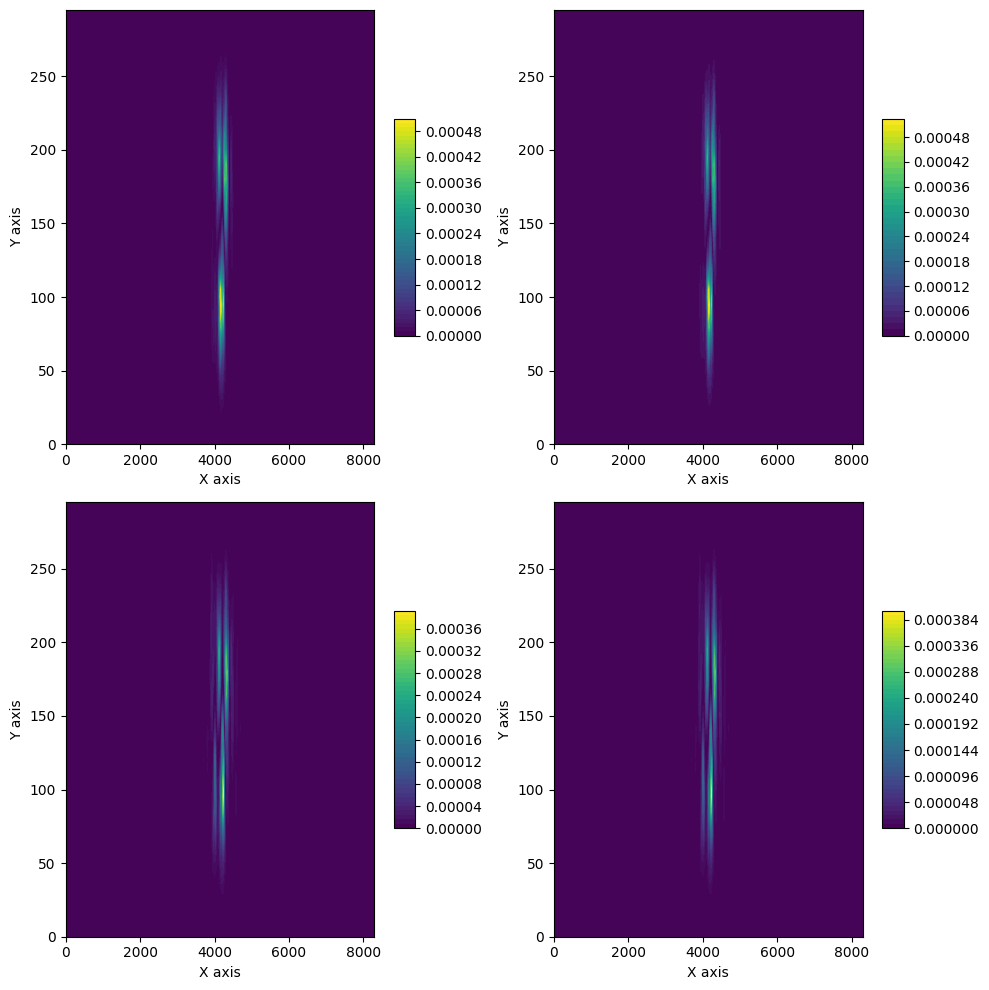

In [15]:
# Load the array
WV_ref_a = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\GS_spinU_wv_disorder_lmbda_{}.npy".format(LMBDA))

WV_ref_b = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\GS_spinD_wv_disorder_lmbda_{}.npy".format(LMBDA))

WV_ex_a = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\FE_spinU_wv_disorder_lmbda_{}.npy".format(LMBDA))

WV_ex_b = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\FE_spinD_wv_disorder_lmbda_{}.npy".format(LMBDA))

WV_ref_a_reshaped = WV_ref_a.reshape((2,2,M,NTOT))

WV_ref_b_reshaped = WV_ref_b.reshape((2,2,M,NTOT))

WV_ex_a_reshaped = WV_ex_a.reshape((2,2,M,NTOT))

WV_ex_b_reshaped = WV_ex_b.reshape((2,2,M,NTOT))


X = np.arange(NTOT)*AX

Y = np.arange(M)*AY

XM, YM = np.meshgrid(X,Y)

# Assuming XM and YM are meshgrids already created along with WV_ref_reshaped data
# You may need to redefine these or ensure they're available in your workspace

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Iterate over each subplot and plot the specific data
i = 0
for ax in np.nditer(axes, flags=['refs_ok']):
    # Get the current axis from the iterator
    ax = ax.item()

    # Select the appropriate slice of the WV_ref_reshaped data
    Z = np.abs(WV_ref_a_reshaped[i//2, i%2, :, :])**2

    # Generate contour plot for the selected data slice
    contourf = ax.contourf(XM, YM, Z, 50, cmap='viridis')  # Using 50 levels for the contour
    
    # Set titles and labels
    #ax.set_title(f'Contour Plot ')
    ax.set_xlabel('X axis')
    ax.set_ylabel('Y axis')

    # Add a color bar specific to each subplot
    fig.colorbar(contourf, ax=ax, shrink=0.5, aspect=10)

    # Increment the index for selecting data slices
    i += 1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()


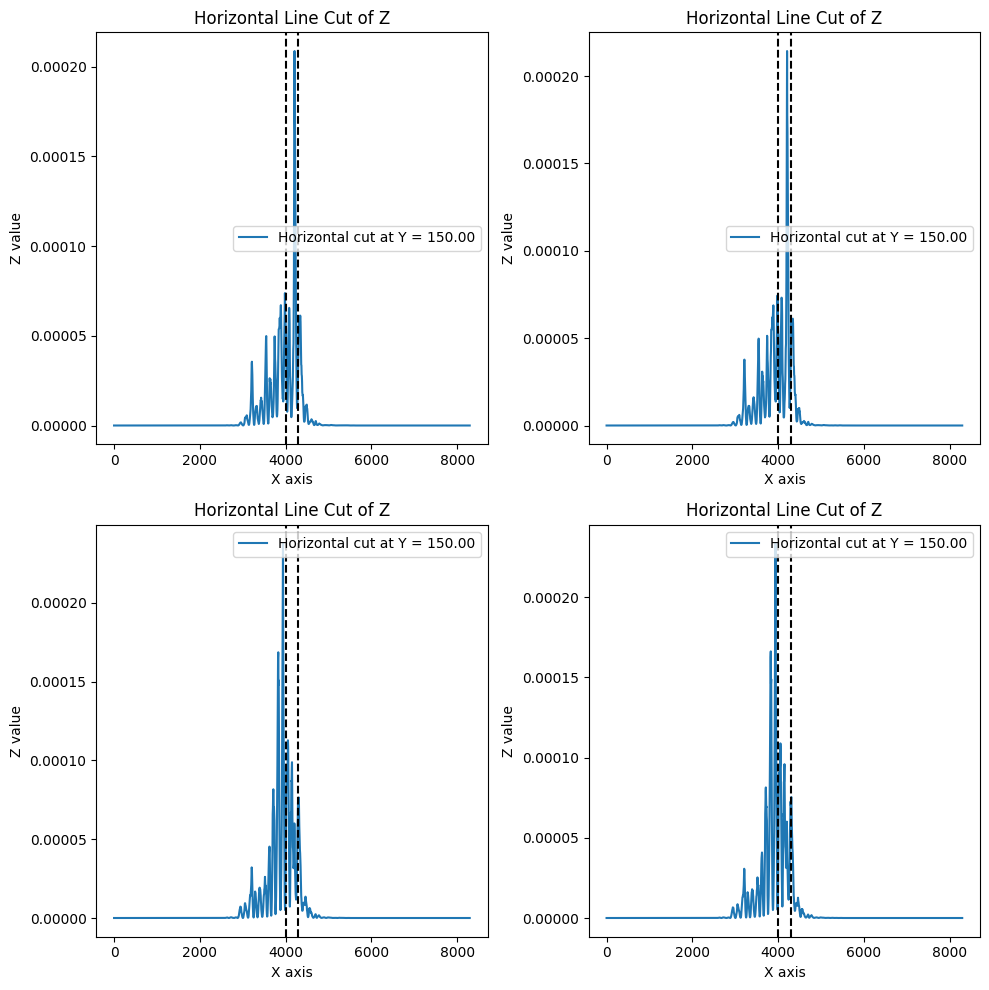

In [16]:
# Choose a specific index for the Y-axis
y_index = 30

# Create a figure and a set of subplots in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Iterate over each subplot and plot the same data
i = 0 
for ax in axes.flatten():

    Z = np.abs(WV_ex_a_reshaped[i//2,i%2,:,:])**2
    # Extract the Z values at this Y index
    Z_line_cut = Z[y_index, :]
    ax.plot(XM[0, :], Z_line_cut, label=f'Horizontal cut at Y = {YM[ y_index,0]:.2f}')
    ax.axvline(x=NSC*AX, color='black', linestyle='dashed')
    ax.axvline(x=(NSC+NSM)*AX, color='black', linestyle='dashed')
    ax.legend()
    ax.set_xlabel('X axis')
    ax.set_ylabel('Z value')
    ax.set_title('Horizontal Line Cut of Z')

    i+=1

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()